# Econ 521 Lab · Difference-in-Differences I
## The 2×2 building block: Medicaid expansion and adult mortality

**Format:** 50 minutes · Python · run the cells top to bottom and fill in the `# TODO` cells.

**Built on**
- Pedro H. C. Sant'Anna, *ECON 730*, Lecture 5 (2×2 DiD) and Lecture 6 (covariates in DiD).
- Baker, Callaway, Cunningham, Goodman-Bacon & Sant'Anna (2025), "Difference-in-Differences Designs: A Practitioner's Guide," *Journal of Economic Literature* (arXiv:2503.13323). We call it **"the guide."**
- Data: the guide's public replication package ([pedrohcgs/JEL-DiD](https://github.com/pedrohcgs/JEL-DiD)). Every point estimate below matches the guide's Tables 2–7.

**By the end of the lab you should be able to**
1. State precisely what DiD estimates (an **ATT**) and what it assumes (**no anticipation + parallel trends**).
2. Compute one 2×2 DiD four ways (four means, pooled OLS, TWFE, first differences) and explain why they must agree.
3. Explain why population weights change the **question**, not just the precision.
4. Judge whether unconditional parallel trends is plausible, and explain why "just add $X$ to the TWFE regression" is not the fix.

| # | Section | Minutes |
|---|---|---|
| 0 | Setup and data | 3 |
| 1 | The missing counterfactual (toy example) | 7 |
| 2 | Parallel trends: the identifying assumption | 6 |
| 3 | DiD by hand: four means | 7 |
| 4 | Regression is a computational device | 8 |
| 5 | Weights define the parameter | 4 |
| 6 | Covariates: when unconditional parallel trends is doubtful | 12 |
| 7 | Wrap-up and exit ticket | 3 |
| A | *Appendix (optional): where the standard errors come from* | — |

---
## 0 · Setup and data

In [24]:
# On Colab or a fresh environment, uncomment the next line (needs Python >= 3.11):
# !pip install -q pyfixest==0.60.0 moderndid==0.2.0

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pyfixest as pf          # fast fixed-effects regressions (Python port of R's fixest)
import moderndid as md         # Python port of R's did / DRDID (Callaway & Sant'Anna; Sant'Anna & Zhao)

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.2f}".format

# Plot style: blue = treated (expansion), orange = comparison; quiet axes and gridlines
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
})


def check(label, value, expected, tol=0.05):
    # Prints whether a TODO answer matches the reference value (never raises)
    if value is None:
        print(f"[ ] {label}: not answered yet")
        return
    ok = abs(float(value) - expected) <= tol
    print(f"[{'✓' if ok else '✗'}] {label}: {float(value):,.2f}" + ("" if ok else "  ← not quite; re-check your formula"))

In [25]:
# County mortality data from the guide's replication package (pinned commit, so results never drift)
DATA_URL = ("https://raw.githubusercontent.com/pedrohcgs/JEL-DiD/"
            "7c60bf753434cddaa24c1f0bb0ef2852777f6d55/data/county_mortality_data.csv")
LOCAL = Path("county_mortality_data.csv")

if LOCAL.exists():
    raw = pd.read_csv(LOCAL)
else:
    raw = pd.read_csv(DATA_URL)
    raw.to_csv(LOCAL, index=False)      # cache a copy for next time

COVS = ["perc_female", "perc_white", "perc_hispanic", "unemp_rate", "poverty_rate", "median_income"]


def build_panel(raw):
    # Rebuilds the guide's analysis sample: 2,604 counties observed every year 2009-2019
    d = raw.copy()
    d["state"] = d["county"].str[-2:]
    d = d[~d["state"].isin(["DC", "DE", "MA", "NY", "VT"])]           # DC + states that expanded before 2014
    d = d.assign(
        perc_white=d.population_20_64_white / d.population_20_64 * 100,
        perc_hispanic=d.population_20_64_hispanic / d.population_20_64 * 100,
        perc_female=d.population_20_64_female / d.population_20_64 * 100,
        unemp_rate=d.unemp_rate * 100,
        median_income=d.median_income / 1000,                          # thousands of dollars
    )
    d = d[["state", "county", "county_code", "year", "population_20_64", "yaca", "crude_rate_20_64"] + COVS]
    d = d.dropna(subset=[c for c in d.columns if c != "yaca"])         # yaca (expansion year) is NaN if never
    d = d.groupby("county_code").filter(lambda g: g["year"].isin([2013, 2014]).sum() == 2)
    d = d.groupby("county_code").filter(lambda g: len(g) == 11)        # full 2009-2019 mortality series
    w13 = d.loc[d["year"] == 2013].set_index("county_code")["population_20_64"]
    d["pop_wt"] = d["county_code"].map(w13)                            # weight = adults aged 20-64 in 2013
    return d.reset_index(drop=True)


panel = build_panel(raw)

# 2x2 design: states expanding in Jan 2014 (treated) vs states that had not expanded by 2019 (comparison)
mort = panel[(panel["yaca"] == 2014) | panel["yaca"].isna() | (panel["yaca"] > 2019)].copy()
mort["treat"] = (mort["yaca"] == 2014).astype(int)

short = mort[mort["year"].isin([2013, 2014])].copy()      # the two periods of the 2x2
short["post"] = (short["year"] == 2014).astype(int)

n_by_group = short.drop_duplicates("county_code")["treat"].value_counts()
print(f"Full panel: {panel.county_code.nunique():,} counties, {panel.year.min()}-{panel.year.max()}")
print(f"2x2 sample: {n_by_group[1]:,} expansion counties, {n_by_group[0]:,} comparison counties")
short[["county", "year", "treat", "post", "crude_rate_20_64", "pop_wt"]].head()

Full panel: 2,604 counties, 2009-2019
2x2 sample: 978 expansion counties, 1,222 comparison counties


,county,year,treat,post,crude_rate_20_64,pop_wt
4,"Autauga County, AL",2013,0,0,526.07,"32,315.00"
5,"Autauga County, AL",2014,0,1,480.77,"32,315.00"
15,"Baldwin County, AL",2013,0,0,398.34,"111,966.00"
16,"Baldwin County, AL",2014,0,1,443.38,"111,966.00"
26,"Barbour County, AL",2013,0,0,480.10,"16,455.00"


| Variable | Meaning |
|---|---|
| `crude_rate_20_64` | **Outcome** $Y_{i,t}$: deaths per 100,000 adults aged 20–64 in county $i$, year $t$ |
| `yaca` | Year the county's state expanded Medicaid under the ACA (`NaN` = not as of 2024) |
| `treat` | $D_i = 1$ if the state expanded in January 2014 |
| `post` | 1 in 2014, 0 in 2013 |
| `pop_wt` | County population aged 20–64 in 2013 (the weight; fixed over time) |
| `perc_*`, `unemp_rate`, `poverty_rate`, `median_income` | County covariates (used in Section 6) |

---
## 1 · The question and the missing counterfactual  *(7 min)*

**Question.** Did the 2014 ACA Medicaid expansion reduce adult mortality in the counties whose states expanded?

**Notation (Sant'Anna's, also used in the guide).** Each county has a treatment-timing group $G_i$:
$G_i = 2014$ if its state expanded in 2014, $G_i = \infty$ if it did not expand (by 2019). Each county has two **potential outcomes** per year:

- $Y_{i,t}(2014)$: mortality in year $t$ if the state expands in 2014;
- $Y_{i,t}(\infty)$: mortality in year $t$ if the state never expands.

**Target parameter: the average treatment effect on the treated**

$$ATT(2014) = \mathbb{E}\big[\,Y_{i,2014}(2014) - Y_{i,2014}(\infty)\;\big|\;G_i = 2014\,\big].$$

It answers an *ex post* question: what did expansion do, on average, **in the places that expanded**? It is not the effect of expanding everywhere (that would be an ATE).

| | $Y_{2013}(\infty)$ | $Y_{2013}(2014)$ | $Y_{2014}(\infty)$ | $Y_{2014}(2014)$ |
|---|:-:|:-:|:-:|:-:|
| Expansion counties ($G=2014$) | ✓ *(no anticipation)* | ✓ | **?** | ✓ |
| Comparison counties ($G=\infty$) | ✓ | — | ✓ | — |

Everything in DiD is about filling the one **?**: what expansion counties' 2014 mortality would have been *without* expansion.

### Warm-up: a world where we can see both potential outcomes
A job-training example from Lecture 5. Low-wage workers select into training. We play God and record both potential wages.

In [26]:
toy = pd.DataFrame({
    "unit":         ["A", "B", "C", "D"],
    "trained":      [1, 1, 0, 0],
    "y_pre":        [20, 18, 30, 28],              # period-1 wage (nobody trained yet)
    "y_post_if_untrained": [22, 20, 32, 30],       # Y_2(inf): God's-eye view
    "y_post_if_trained":   [27, 24, np.nan, np.nan],  # Y_2(2): only relevant for trained units
}).set_index("unit")
toy["y_post"] = np.where(toy["trained"] == 1, toy["y_post_if_trained"], toy["y_post_if_untrained"])  # observed

true_att = (toy["y_post_if_trained"] - toy["y_post_if_untrained"])[toy["trained"] == 1].mean()
print(f"True ATT (needs the God's-eye column): {true_att:.2f}")
toy

True ATT (needs the God's-eye column): 4.50


,trained,y_pre,y_post_if_untrained,y_post_if_trained,y_post
unit,,,,,
A,1,20,22,27.00,27.00
B,1,18,20,24.00,24.00
C,0,30,32,NaN,32.00
D,0,28,30,NaN,30.00


In [27]:
# TODO 1 — solution
T, C = toy[toy["trained"] == 1], toy[toy["trained"] == 0]

est_cross = T["y_post"].mean() - C["y_post"].mean()                  # 25.5 - 31.0
est_before_after = T["y_post"].mean() - T["y_pre"].mean()            # 25.5 - 19.0
est_did = est_before_after - (C["y_post"].mean() - C["y_pre"].mean())  # 6.5 - 2.0

check("(a) cross-section", est_cross, -5.5)
check("(b) before-after", est_before_after, 6.5)
check("(c) DiD", est_did, 4.5)

[✓] (a) cross-section: -5.50
[✓] (b) before-after: 6.50
[✓] (c) DiD: 4.50


**What went wrong, and what went right.** Each estimator equals the ATT (4.5) plus a bias:

| Estimator | Value | = ATT + bias | Source of the bias |
|---|:-:|:-:|---|
| (a) Cross-section after | −5.5 | 4.5 + (−10) | **Selection**: trainees would have earned 10 less anyway |
| (b) Before–after | 6.5 | 4.5 + 2 | **Time trend**: everyone's wage grows by 2 |
| (c) DiD | 4.5 | 4.5 + 0 | The untrained group's change (+2) is exactly the change trainees would have had |

DiD works here because the two groups have **different levels but the same trend** in untreated outcomes. That is the whole assumption.

*Quick think (30 sec):* if unit C's untrained post wage were 35 instead of 32, which estimators change, and is DiD still right?

---
## 2 · Parallel trends: the identifying assumption  *(6 min)*

| Assumption | Formal statement (2×2) | In Medicaid words |
|---|---|---|
| **SUTVA** | County $i$'s outcome depends only on its own treatment | No spillovers from neighbouring states' expansions |
| **No anticipation** | $Y_{i,2013}(2014) = Y_{i,2013}(\infty)$ | Mortality in 2013 was not affected by the coming expansion |
| **Parallel trends (PT)** | $\mathbb{E}[Y_{2014}(\infty) - Y_{2013}(\infty)\mid G=2014] = \mathbb{E}[Y_{2014}(\infty) - Y_{2013}(\infty)\mid G=\infty]$ | Without expansion, mortality in expansion counties would have changed by the same amount, on average, as in non-expansion counties |

**What PT allows:** permanent level differences between groups (expansion counties have lower mortality — fine).
**What PT rules out:** differential *trends* in untreated outcomes, e.g. states that expanded because their mortality was about to improve.

Under these three assumptions,

$$ATT(2014) = \underbrace{\big(\mathbb{E}[Y_{2014}\mid G{=}2014]-\mathbb{E}[Y_{2013}\mid G{=}2014]\big)}_{\text{treated change}} - \underbrace{\big(\mathbb{E}[Y_{2014}\mid G{=}\infty]-\mathbb{E}[Y_{2013}\mid G{=}\infty]\big)}_{\text{comparison change}}.$$

Two points from the guide (§3.2) worth remembering:
- PT does not need outside randomization (random adoption would imply it, but then DiD isn't needed). It is a restriction on how untreated outcomes evolve, and it involves a counterfactual, so it is **untestable**. Pre-period data can make it more or less believable (Part II of the lab).
- Whether PT is plausible depends on **why units chose treatment**. If state legislatures chose based on long-run mortality *levels*, PT can hold. If they also reacted to a temporary 2013 mortality shock, PT needs much stronger restrictions on how mortality evolves (Ghanem, Sant'Anna & Wüthrich).

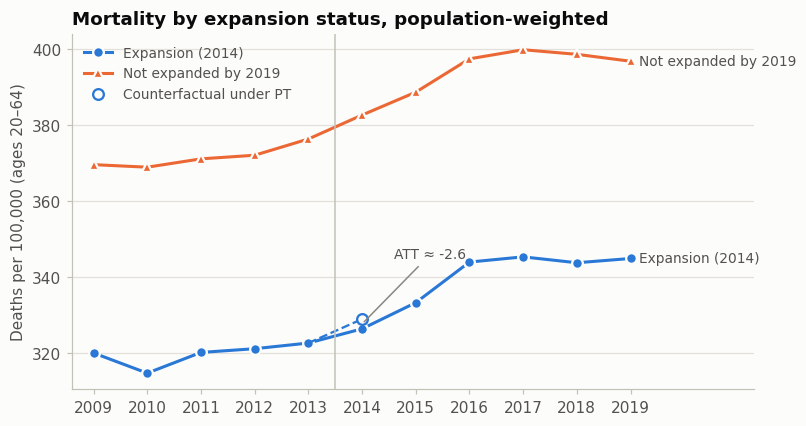

In [28]:
# Population-weighted mean mortality by group, 2009-2019 (the guide's Figure 2)
trends = (mort.assign(group=np.where(mort["treat"] == 1, "Expansion (2014)", "Not expanded by 2019"))
              .groupby(["group", "year"])
              .apply(lambda g: np.average(g["crude_rate_20_64"], weights=g["pop_wt"]))
              .unstack("group"))

# Parallel-trends counterfactual for 2014: treated 2013 level + comparison change 2013->2014
cf_2014 = (trends.loc[2013, "Expansion (2014)"]
           + trends.loc[2014, "Not expanded by 2019"] - trends.loc[2013, "Not expanded by 2019"])

fig, ax = plt.subplots()
for col, color, marker in [("Expansion (2014)", BLUE, "o"), ("Not expanded by 2019", ORANGE, "^")]:
    ax.plot(trends.index, trends[col], color=color, marker=marker, ms=7, mec=SURFACE, mew=1.5, label=col)
    ax.annotate(col, (2019.15, trends.loc[2019, col]), color=INK2, va="center", fontsize=9)
ax.plot([2013, 2014], [trends.loc[2013, "Expansion (2014)"], cf_2014], ls="--", color=BLUE, lw=1.5)
ax.plot(2014, cf_2014, "o", mfc=SURFACE, mec=BLUE, mew=1.5, ms=7, label="Counterfactual under PT")
ax.annotate(f"ATT ≈ {trends.loc[2014, 'Expansion (2014)'] - cf_2014:.1f}",
            xy=(2014, (cf_2014 + trends.loc[2014, 'Expansion (2014)']) / 2), xytext=(2014.6, 345),
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.axvline(2013.5, color=AXIS, lw=1)
ax.set_xticks(range(2009, 2020))
ax.set_xlim(2008.6, 2021.3)
ax.set_ylabel("Deaths per 100,000 (ages 20–64)")
ax.set_title("Mortality by expansion status, population-weighted")
ax.legend(loc="upper left", fontsize=9)
plt.show()

The hollow dot is the counterfactual PT delivers: start from expansion counties' 2013 level and add the comparison group's 2013→2014 change. The vertical gap at 2014 is the (weighted) ATT.

💬 **Discuss with your neighbour (1 min):** name one concrete story that would make PT fail here. *(Hints: the opioid epidemic hit regions differently; non-expansion states are mostly in the South; the recovery from the Great Recession was uneven.)*

---
## 3 · DiD by hand: four means  *(7 min)*

Replace each population expectation with its sample analogue. With weights $\omega_i$,
$$\widehat{ATT} = \big(\bar Y^{\omega}_{T,2014} - \bar Y^{\omega}_{T,2013}\big) - \big(\bar Y^{\omega}_{C,2014} - \bar Y^{\omega}_{C,2013}\big).$$
The function below builds the guide's **Table 2**.

In [29]:
def two_by_two_table(df, weights=None):
    # Rows: 2013, 2014, change. Columns: expansion, comparison, gap.
    def m(g):
        return np.average(g["crude_rate_20_64"], weights=None if weights is None else g[weights])
    means = df.groupby(["year", "treat"]).apply(m).unstack("treat")
    tab = pd.DataFrame({"Expansion": means[1], "No expansion": means[0]})
    tab.loc["Change 2013→14"] = tab.loc[2014] - tab.loc[2013]
    tab["Gap (E − N)"] = tab["Expansion"] - tab["No expansion"]
    return tab


unw = two_by_two_table(short)
wtd = two_by_two_table(short, weights="pop_wt")
pd.concat({"Unweighted": unw, "Population-weighted": wtd}, axis=1)

Unweighted                          Population-weighted  \
                Expansion No expansion Gap (E − N)           Expansion   
year                                                                     
2013               419.23       474.00      -54.77              322.72   
2014               428.50       483.15      -54.65              326.46   
Change 2013→14       9.27         9.15        0.12                3.74   

                                         
               No expansion Gap (E − N)  
year                                     
2013                 376.40      -53.68  
2014                 382.70      -56.25  
Change 2013→14         6.30       -2.56

In [30]:
# Worked example: the unweighted DiD from the four unweighted means
did_unweighted = (unw.loc[2014, "Expansion"] - unw.loc[2013, "Expansion"]) - \
                 (unw.loc[2014, "No expansion"] - unw.loc[2013, "No expansion"])
print(f"Unweighted 2x2 DiD: {did_unweighted:.2f} deaths per 100,000")
print(f"Same thing as a change in the gap: {unw.loc[2014, 'Gap (E − N)'] - unw.loc[2013, 'Gap (E − N)']:.2f}")

Unweighted 2x2 DiD: 0.12 deaths per 100,000
Same thing as a change in the gap: 0.12


In [31]:
# TODO 2 — solution
did_weighted = (wtd.loc[2014, "Expansion"] - wtd.loc[2013, "Expansion"]) - \
               (wtd.loc[2014, "No expansion"] - wtd.loc[2013, "No expansion"])

check("Weighted 2x2 DiD", did_weighted, -2.56)

[✓] Weighted 2x2 DiD: -2.56


**Reading the table** (guide, Table 2). Unweighted: mortality rose by 9.3 in expansion counties and 9.1 in comparison counties, so the DiD is **+0.1** deaths per 100,000. Population-weighted: +3.7 vs +6.3, so the DiD is **−2.6**.

Same data, same design, opposite signs. Hold that thought until Section 5.

---
## 4 · Regression is a computational device  *(8 min)*

Three regressions give **numerically identical** $\hat\beta$ in a balanced 2×2 panel (guide, Table 3):

| Spec | Regression | Rows |
|---|---|---|
| (1) Pooled OLS | $Y_{it} = \beta_0 + \beta_1 D_i + \beta_2 \text{Post}_t + \beta^{2\times2}(D_i \times \text{Post}_t) + \varepsilon_{it}$ | $2n$ |
| (2) TWFE | $Y_{it} = \alpha_i + \lambda_t + \beta^{2\times2} D_{it} + \varepsilon_{it}$ | $2n$ |
| (3) First differences | $\Delta Y_i = \delta + \beta^{2\times2} D_i + u_i$ | $n$ |

Why? With four cells and four free parameters, OLS just reproduces the four means. The causal interpretation comes from the **identification argument** in Section 2, not from the regression. (Lecture 5's warning: this equivalence is special to the 2×2. With more periods, a single static TWFE coefficient stops equalling an average ATT, and with staggered timing it can even put negative weights on some effects. That is Part II.)

In [32]:
rows = []
for wlabel, w in [("Unweighted", None), ("Pop.-weighted", "pop_wt")]:
    for spec, fml in [("(1) Pooled OLS", "crude_rate_20_64 ~ treat*post"),
                      ("(2) TWFE", "crude_rate_20_64 ~ treat:post | county_code + year")]:
        fit = pf.feols(fml, data=short, weights=w, vcov={"CRV1": "county_code"})
        rows.append({"Weights": wlabel, "Spec": spec, "β̂": fit.coef()["treat:post"],
                     "SE (county-clustered)": fit.se()["treat:post"], "Rows": len(short)})
reg_table = pd.DataFrame(rows).set_index(["Weights", "Spec"])
reg_table

β̂  SE (county-clustered)  Rows
Weights       Spec                                             
Unweighted    (1) Pooled OLS  0.12                   3.75  4400
              (2) TWFE        0.12                   3.75  4400
Pop.-weighted (1) Pooled OLS -2.56                   1.49  4400
              (2) TWFE       -2.56                   1.49  4400

In [33]:
# Each coefficient of the pooled regression is a combination of the four unweighted means
b = pf.feols("crude_rate_20_64 ~ treat*post", data=short).coef()
pd.DataFrame({
    "Combination of coefficients": ["β0", "β0 + β1", "β0 + β2", "β0 + β1 + β2 + β3"],
    "Value": [b["Intercept"], b["Intercept"] + b["treat"], b["Intercept"] + b["post"], b.sum()],
    "Sample mean": [unw.loc[2013, "No expansion"], unw.loc[2013, "Expansion"],
                    unw.loc[2014, "No expansion"], unw.loc[2014, "Expansion"]],
}, index=["Comparison, 2013", "Expansion, 2013", "Comparison, 2014", "Expansion, 2014"])

,Combination of coefficients,Value,Sample mean
"Comparison, 2013",β0,474.00,474.00
"Expansion, 2013",β0 + β1,419.23,419.23
"Comparison, 2014",β0 + β2,483.15,483.15
"Expansion, 2014",β0 + β1 + β2 + β3,428.50,428.50


Now the first-difference version. One row per county: $\Delta Y_i = Y_{i,2014} - Y_{i,2013}$. Differencing removes everything about a county that does not change over time, which is exactly why the level gap (−54.8) is harmless. We also store 2013 covariates and their 2013→14 changes for Section 6.

In [34]:
wide = short.pivot(index="county_code", columns="year", values="crude_rate_20_64")
wideX = short.pivot(index="county_code", columns="year", values=COVS)

ld = short[short["year"] == 2013].set_index("county_code")[["state", "treat", "pop_wt"] + COVS].copy()
ld["dy"] = wide[2014] - wide[2013]                         # long (first) difference of the outcome
for c in COVS:
    ld["d_" + c] = wideX[(c, 2014)] - wideX[(c, 2013)]     # change in each covariate
ld = ld.reset_index()
ld[["county_code", "state", "treat", "pop_wt", "dy"]].head()

,county_code,state,treat,pop_wt,dy
0,1001,AL,0,"32,315.00",-45.30
1,1003,AL,0,"111,966.00",45.05
2,1005,AL,0,"16,455.00",0.85
3,1007,AL,0,"14,002.00",-28.24
4,1009,AL,0,"33,238.00",118.27


In [35]:
# TODO 3 — solution
fit_fd_unw = pf.feols("dy ~ treat", data=ld, vcov={"CRV1": "county_code"})
fit_fd_wtd = pf.feols("dy ~ treat", data=ld, weights="pop_wt", vcov={"CRV1": "county_code"})

check("FD, unweighted", None if fit_fd_unw is None else fit_fd_unw.coef()["treat"], 0.12)
check("FD, weighted",   None if fit_fd_wtd is None else fit_fd_wtd.coef()["treat"], -2.56)

[✓] FD, unweighted: 0.12
[✓] FD, weighted: -2.56


In [36]:
# Add your first-difference results to the table (guide, Table 3)
for wlabel, fit in [("Unweighted", fit_fd_unw), ("Pop.-weighted", fit_fd_wtd)]:
    if fit is not None:
        reg_table.loc[(wlabel, "(3) First differences"), :] = [fit.coef()["treat"], fit.se()["treat"], len(ld)]
reg_table["Rows"] = reg_table["Rows"].astype(int)
reg_table.reindex([(w, s) for w in ["Unweighted", "Pop.-weighted"]
                   for s in ["(1) Pooled OLS", "(2) TWFE", "(3) First differences"] if (w, s) in reg_table.index])

β̂  SE (county-clustered)  Rows
Weights       Spec                                                    
Unweighted    (1) Pooled OLS         0.12                   3.75  4400
              (2) TWFE               0.12                   3.75  4400
              (3) First differences  0.12                   3.75  2200
Pop.-weighted (1) Pooled OLS        -2.56                   1.49  4400
              (2) TWFE              -2.56                   1.49  4400
              (3) First differences -2.56                   1.49  2200

**Same $\hat\beta$, and the same SE once we cluster by county.** But what if we *don't* cluster? The standard error should describe where the randomness in the estimate comes from. The guide treats counties as sampled units (cluster by county). Because expansion was decided by **states**, clustering by state is also defensible (guide §3.3); with few clusters that brings its own problems.

In [37]:
se_rows = []
for wlabel, w in [("Unweighted", None), ("Pop.-weighted", "pop_wt")]:
    for label, fml, vc in [
        ("Pooled OLS, iid SEs (treats 2n rows as independent)", "crude_rate_20_64 ~ treat*post", "iid"),
        ("TWFE, iid SEs", "crude_rate_20_64 ~ treat:post | county_code + year", "iid"),
        ("TWFE, clustered by county", "crude_rate_20_64 ~ treat:post | county_code + year", {"CRV1": "county_code"}),
        ("TWFE, clustered by state", "crude_rate_20_64 ~ treat:post | county_code + year", {"CRV1": "state"}),
    ]:
        fit = pf.feols(fml, data=short, weights=w, vcov=vc)
        se_rows.append({"Weights": wlabel, "Standard error": label, "SE": fit.se()["treat:post"]})
se_table = pd.DataFrame(se_rows).pivot(index="Standard error", columns="Weights", values="SE")
se_table.loc[pd.unique(pd.DataFrame(se_rows)["Standard error"]), ["Unweighted", "Pop.-weighted"]]

Weights,Unweighted,Pop.-weighted
Standard error,,
"Pooled OLS, iid SEs (treats 2n rows as independent)",9.07,6.86
"TWFE, iid SEs",3.78,1.61
"TWFE, clustered by county",3.75,1.49
"TWFE, clustered by state",3.72,1.98


The pooled regression with iid SEs ignores that the 2013 and 2014 observations of a county are strongly correlated, so it gets the uncertainty badly wrong (here, too **large**: mortality is persistent, and differencing removes most of the noise). Rule of thumb from Lecture 5: **always cluster at least at the unit level**; think about whether the level of treatment assignment (states) matters for your question.

---
## 5 · Weights define the parameter  *(4 min)*

The unweighted ATT averages over **counties**; the population-weighted ATT averages over **people**:

$$ATT = \mathbb{E}[Y_{2014}(2014) - Y_{2014}(\infty)\mid G = 2014] \qquad\text{vs.}\qquad ATT_\omega = \mathbb{E}_\omega[\,\cdot\,\mid G = 2014].$$

Both are valid ATTs; they answer different questions. If effects (or trends) differ between small rural counties and large urban ones, the two can differ a lot. Weighting also changes the PT assumption itself: weighted PT is a statement about population-weighted trends.

In [38]:
tr = ld[ld["treat"] == 1]
ca = tr["state"] == "CA"
big = tr["pop_wt"] >= tr["pop_wt"].quantile(0.90)
print(f"California: {ca.mean():.1%} of expansion counties but {tr.loc[ca, 'pop_wt'].sum() / tr['pop_wt'].sum():.1%} of expansion-county adults")
print(f"Largest 10% of expansion counties hold {tr.loc[big, 'pop_wt'].sum() / tr['pop_wt'].sum():.1%} of expansion-county adults\n")

# Unweighted DiD within quartiles of county size
ld["size_quartile"] = pd.qcut(ld["pop_wt"], 4, labels=["Q1 (smallest)", "Q2", "Q3", "Q4 (largest)"])
by_size = ld.groupby("size_quartile", observed=True).apply(lambda g: pd.Series({
    "DiD (deaths/100k)": g.loc[g.treat == 1, "dy"].mean() - g.loc[g.treat == 0, "dy"].mean(),
    "Expansion counties": g["treat"].sum(),
    "Comparison counties": (1 - g["treat"]).sum(),
    "Median adults": g["pop_wt"].median(),
}))
by_size.astype({"Expansion counties": int, "Comparison counties": int, "Median adults": int})

California: 5.7% of expansion counties but 27.6% of expansion-county adults
Largest 10% of expansion counties hold 67.7% of expansion-county adults



,DiD (deaths/100k),Expansion counties,Comparison counties,Median adults
size_quartile,,,,
Q1 (smallest),-9.03,225,325,5970
Q2,12.61,237,313,12394
Q3,-0.11,245,305,26106
Q4 (largest),-2.09,271,279,107518


The DiD bounces around across size quartiles (these are noisy). The unweighted estimate gives the many small counties most of the say; the weighted estimate is driven by the few large ones. Neither is "the right one" in general: **pick the weights that match your question before you see the results** (the guide argues the per-person parameter is more policy-relevant here).

Also note (Solon, Haider & Wooldridge 2015): weighting "to improve precision" quietly changes the target parameter whenever effects are heterogeneous. Comparing weighted and unweighted estimates is **not** a robustness check; it is a comparison of two different parameters.

---
## 6 · Covariates: when unconditional parallel trends is doubtful  *(12 min)*

### 6a · Balance: do the groups look alike?
If a variable drives mortality **trends** and is unbalanced across groups, unconditional PT is in trouble. A scale-free measure of imbalance is the normalized difference (Imbens & Rubin):
$$\text{Norm. diff} = \frac{\bar X_T - \bar X_C}{\sqrt{(S_T^2 + S_C^2)/2}}, \qquad |\cdot| > 0.25 \text{ is a common red flag}.$$

In [39]:
LABELS = {"perc_female": "% Female", "perc_white": "% White", "perc_hispanic": "% Hispanic",
          "unemp_rate": "Unemployment rate", "poverty_rate": "Poverty rate", "median_income": "Median income ($K)"}


def wvar(x, w):
    w = np.asarray(w, float) / np.sum(w)
    m = np.sum(w * x)
    return np.sum(w * (x - m) ** 2) / (1 - np.sum(w ** 2))       # unbiased weighted variance


def balance(df, prefix="", weights=None):
    rows = {}
    for c in COVS:
        x, d = df[prefix + c].to_numpy(float), df["treat"].to_numpy()
        w = np.ones(len(df)) if weights is None else df[weights].to_numpy(float)
        m1, m0 = np.average(x[d == 1], weights=w[d == 1]), np.average(x[d == 0], weights=w[d == 0])
        nd = (m1 - m0) / np.sqrt((wvar(x[d == 1], w[d == 1]) + wvar(x[d == 0], w[d == 0])) / 2)
        rows[LABELS[c]] = {"Non-adopt": m0, "Adopt": m1, "Norm. diff": nd}
    return pd.DataFrame(rows).T


bal = pd.concat({
    ("2013 levels", "Unweighted"): balance(ld),
    ("2013 levels", "Weighted"): balance(ld, weights="pop_wt"),
    ("2014−2013 changes", "Unweighted"): balance(ld, prefix="d_"),
    ("2014−2013 changes", "Weighted"): balance(ld, prefix="d_", weights="pop_wt"),
}, axis=1)
display(bal["2013 levels"])          # guide, Table 4 (top panel)
display(bal["2014−2013 changes"])    # guide, Table 4 (bottom panel)

Unweighted                   Weighted                 
                    Non-adopt Adopt Norm. diff Non-adopt Adopt Norm. diff
% Female                49.43 49.33      -0.03     50.48 50.07      -0.24
% White                 81.64 90.48       0.59     77.91 79.54       0.11
% Hispanic               9.64  8.23      -0.10     17.01 18.86       0.11
Unemployment rate        7.61  8.01       0.16      7.00  8.01       0.50
Poverty rate            19.28 16.53      -0.42     17.24 15.29      -0.37
Median income ($K)      43.04 47.97       0.43     49.31 57.86       0.68

Unweighted                   Weighted                 
                    Non-adopt Adopt Norm. diff Non-adopt Adopt Norm. diff
% Female                -0.02 -0.02      -0.00      0.02  0.01      -0.09
% White                 -0.21 -0.21       0.01     -0.32 -0.33      -0.04
% Hispanic               0.20  0.21       0.04      0.25  0.33       0.29
Unemployment rate       -1.16 -1.30      -0.21     -1.08 -1.36      -0.55
Poverty rate            -0.55 -0.28       0.14     -0.41 -0.35       0.05
Median income ($K)       0.98  1.11       0.06      1.10  1.74       0.32

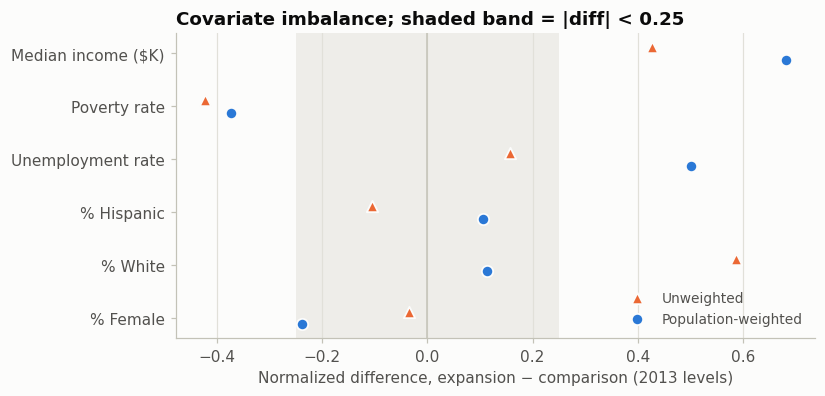

In [40]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ylab = list(LABELS.values())
ypos = np.arange(len(ylab))
ax.axvspan(-0.25, 0.25, color=GRID, alpha=0.5, lw=0)
ax.axvline(0, color=AXIS, lw=1)
ax.scatter(bal[("2013 levels", "Unweighted", "Norm. diff")], ypos + 0.12, color=ORANGE, marker="^",
           s=55, edgecolor=SURFACE, lw=1.2, zorder=3, label="Unweighted")
ax.scatter(bal[("2013 levels", "Weighted", "Norm. diff")], ypos - 0.12, color=BLUE, marker="o",
           s=55, edgecolor=SURFACE, lw=1.2, zorder=3, label="Population-weighted")
ax.set_yticks(ypos, ylab)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Normalized difference, expansion − comparison (2013 levels)")
ax.set_title("Covariate imbalance; shaded band = |diff| < 0.25")
ax.legend(loc="lower right", fontsize=9)
plt.show()

Expansion counties were richer and had less poverty but **higher** unemployment; with weights, income (0.68), unemployment (0.50) and poverty (−0.37) all exceed 0.25. If mortality trends differed by income or poverty in the 2010s (they did), unconditional PT is questionable.

The bottom table looks at **changes** 2013→14: unemployment was higher in expansion counties in 2013 but fell faster (weighted normalized difference −0.55). Is that a red flag for PT, or an effect of the expansion? It depends on whether expansion could move unemployment: deciding what is a covariate and what is an outcome is a question about the economics, not the data.

A common but wrong argument: "DiD differences out baseline differences." It differences out **levels** of the outcome, not differences in **trends** that baseline covariates predict.

### 6b · Conditional parallel trends
**Assumption CPT:** PT holds *among counties with the same covariates*:
$$\mathbb{E}[Y_{2014}(\infty) - Y_{2013}(\infty) \mid X, G=2014] = \mathbb{E}[Y_{2014}(\infty) - Y_{2013}(\infty) \mid X, G=\infty],$$
plus **overlap** (every treated $X$ has comparison units nearby: $P(G{=}2014\mid X) < 1$). Then
$$ATT = \underbrace{\mathbb{E}[\Delta Y \mid G{=}2014]}_{\text{treated change}} - \underbrace{\mathbb{E}\big[\,\mathbb{E}[\Delta Y\mid X, G{=}\infty]\;\big|\;G{=}2014\big]}_{\text{comparison change for treated-like }X}.$$
In words: compare each treated county's change with the change of comparison counties *that look like it*, then average over treated counties. Use **pre-treatment** covariates; a covariate that the treatment itself could move is a **bad control**.

### 6c · "Just add $X$ to the TWFE regression?"
The most common practice. In two periods, TWFE with covariates is a first-difference regression. Adding $X_{it}$ to TWFE controls for **changes** $\Delta X$; adding $\text{Post}_t \times X_{i,2013}$ controls for baseline **levels**.

In [41]:
X_LEVELS = " + ".join(COVS)
X_CHANGES = " + ".join("d_" + c for c in COVS)
rows = []
for wlabel, w in [("Unweighted", None), ("Pop.-weighted", "pop_wt")]:
    for label, fml in [("No covariates", "dy ~ treat"),
                       ("+ 2013 levels of X   (TWFE with Post × X_2013)", f"dy ~ treat + {X_LEVELS}"),
                       ("+ changes in X       (TWFE with X_it)", f"dy ~ treat + {X_CHANGES}")]:
        fit = pf.feols(fml, data=ld, weights=w, vcov={"CRV1": "county_code"})
        rows.append({"Weights": wlabel, "Specification": label, "β̂_treat": fit.coef()["treat"], "SE": fit.se()["treat"]})
twfe_x = pd.DataFrame(rows).set_index(["Weights", "Specification"])
twfe_x

β̂_treat   SE
Weights       Specification                                                
Unweighted    No covariates                                       0.12 3.75
              + 2013 levels of X   (TWFE with Post × X_2013)     -2.35 4.29
              + changes in X       (TWFE with X_it)              -0.49 3.83
Pop.-weighted No covariates                                      -2.56 1.49
              + 2013 levels of X   (TWFE with Post × X_2013)     -2.56 1.78
              + changes in X       (TWFE with X_it)              -1.37 1.62

Unweighted, the estimate moves from 0.12 to −2.35 to −0.49 depending on how $X$ enters (guide, Table 5). Which, if any, is the ATT under CPT? Caetano & Callaway (2024) show TWFE-with-covariates recovers the ATT only under **extra** assumptions:
1. **Homogeneous effects across $X$.** The regression forces $ATT(x)$ to be the same for every $x$; otherwise $\hat\beta$ is a weighted average with non-transparent (possibly negative) weights.
2. **Levels vs changes.** $X_{it}$ in TWFE controls for $\Delta X$: "areas that are poor are not the same as areas that are becoming poor."
3. **Linearity.** A linear projection is not the conditional expectation.
4. **Bad controls.** Time-varying $X$ that the policy affects (e.g. 2014 poverty) contaminates the estimate (Caetano, Callaway, Payne & Rodrigues 2022).

### 6d · Forward engineering: estimate the identification formula directly
**Regression adjustment (RA)**, Heckman, Ichimura & Todd (1997): fit a model for $\mathbb{E}[\Delta Y\mid X, G{=}\infty]$ **on comparison counties only**, predict it for treated counties, and subtract.

In [42]:
# TODO 4 — solution
comp, trt = ld[ld["treat"] == 0], ld[ld["treat"] == 1]

or_model = sm.WLS(comp["dy"], sm.add_constant(comp[COVS]), weights=comp["pop_wt"]).fit()
pred_trt = or_model.predict(sm.add_constant(trt[COVS]))
att_ra = np.average(trt["dy"] - pred_trt, weights=trt["pop_wt"])

print(f"Observed change, expansion counties:          {np.average(trt['dy'], weights=trt['pop_wt']):6.2f}")
print(f"Predicted untreated change for those counties: {np.average(pred_trt, weights=trt['pop_wt']):6.2f}")
print(f"Raw change, comparison counties:               {np.average(comp['dy'], weights=comp['pop_wt']):6.2f}")
check("RA DiD (weighted)", att_ra, -3.46)

Observed change, expansion counties:            3.74
Predicted untreated change for those counties:   7.20
Raw change, comparison counties:                 6.30
[✓] RA DiD (weighted): -3.46


**Reading it.** Comparison counties' mortality rose by 6.3. But comparison counties *that look like expansion counties* rose by about 7.2. Expansion counties rose by only 3.7, so $\widehat{ATT}_{RA} \approx 3.7 - 7.2 = -3.5$.

**Inverse probability weighting (IPW)**, Abadie (2005): instead of modelling outcomes, model **who expands**, $p(X) = P(G{=}2014\mid X)$, and reweight comparison counties by $p(X)/(1-p(X))$ so their covariate distribution matches the treated.

**Doubly robust (DR)**, Sant'Anna & Zhao (2020): combine both. It is consistent if **either** the outcome model **or** the propensity score is right, and *locally* efficient when both are. DR is the default in Callaway & Sant'Anna's `did` / `att_gt`.

`moderndid` ports Sant'Anna & Zhao's `DRDID` estimators. The low-level functions take the two outcome vectors, the treatment dummy and a covariate matrix **that must include an intercept column**.

In [43]:
y1 = wide.loc[ld["county_code"], 2014].to_numpy()
y0 = wide.loc[ld["county_code"], 2013].to_numpy()
D = ld["treat"].to_numpy()
Xmat = np.column_stack([np.ones(len(ld)), ld[COVS].to_numpy()])        # intercept + 2013 covariates

rows = []
for wlabel, w in [("Unweighted", None), ("Pop.-weighted", ld["pop_wt"].to_numpy())]:
    for name, fn in [("Regression adjustment", md.reg_did_panel),
                     ("IPW (normalized)", md.std_ipw_did_panel),
                     ("Doubly robust", md.drdid_panel)]:
        r = fn(y1, y0, D, Xmat, i_weights=w)
        rows.append({"Weights": wlabel, "Estimator": name, "ATT": r.att, "SE": r.se})
cov_table = pd.DataFrame(rows).set_index(["Weights", "Estimator"])
cov_table

ATT   SE
Weights       Estimator                       
Unweighted    Regression adjustment -1.62 4.61
              IPW (normalized)      -0.86 4.58
              Doubly robust         -1.23 4.88
Pop.-weighted Regression adjustment -3.46 2.38
              IPW (normalized)      -3.84 3.22
              Doubly robust         -3.76 3.09

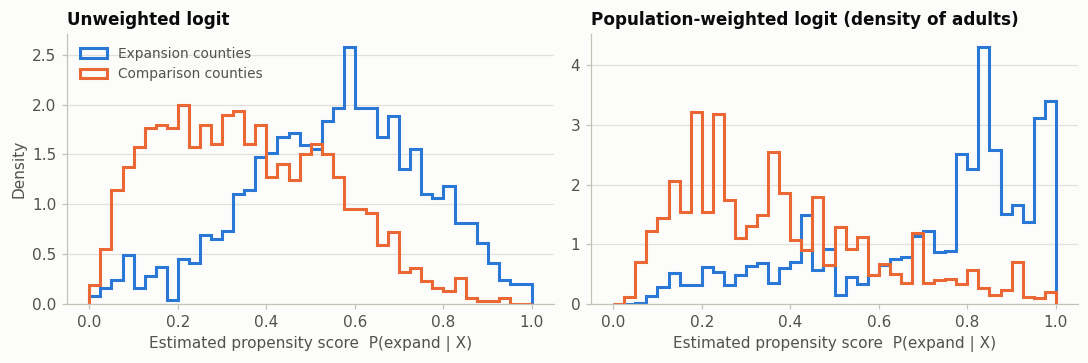

Unweighted: comparison counties with p(X) > 0.995 (trimmed by default): 0;  share of expansion-county adults with p(X) > 0.95: 1.1%
  Weighted: comparison counties with p(X) > 0.995 (trimmed by default): 3;  share of expansion-county adults with p(X) > 0.95: 16.3%

R² of the outcome-change model (comparison counties, weighted): 0.006
Pseudo-R² of the propensity-score logit (unweighted):            0.155


In [44]:
# Overlap check: propensity scores from a logit on 2013 covariates, unweighted and population-weighted
# (DRDID / att_gt fit the weighted version when you pass weights)
Xc = sm.add_constant(ld[COVS])
w_norm = ld["pop_wt"] / ld["pop_wt"].mean()
ps_unw = sm.GLM(ld["treat"], Xc, family=sm.families.Binomial()).fit().predict(Xc).to_numpy()
ps_wtd = sm.GLM(ld["treat"], Xc, family=sm.families.Binomial(), freq_weights=w_norm).fit().predict(Xc).to_numpy()

bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, ps, w, title in [(axes[0], ps_unw, None, "Unweighted logit"),
                         (axes[1], ps_wtd, ld["pop_wt"].to_numpy(), "Population-weighted logit (density of adults)")]:
    for grp, color, name in [(1, BLUE, "Expansion counties"), (0, ORANGE, "Comparison counties")]:
        m = D == grp
        ax.hist(ps[m], bins=bins, weights=None if w is None else w[m], density=True,
                histtype="step", lw=2, color=color, label=name)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Estimated propensity score  P(expand | X)")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

wt = ld["pop_wt"].to_numpy()
for label, ps in [("Unweighted", ps_unw), ("Weighted", ps_wtd)]:
    print(f"{label:>10}: comparison counties with p(X) > 0.995 (trimmed by default): {(ps[D == 0] > 0.995).sum()};  "
          f"share of expansion-county adults with p(X) > 0.95: {wt[(D == 1) & (ps > 0.95)].sum() / wt[D == 1].sum():.1%}")

# How well do the covariates predict trends vs. treatment? (guide, Table 6)
comp_ = ld[ld["treat"] == 0]
r2_or = sm.WLS(comp_["dy"], sm.add_constant(comp_[COVS]), weights=comp_["pop_wt"]).fit().rsquared
pr2_ps = sm.Logit(ld["treat"], Xc).fit(disp=0).prsquared
print(f"\nR² of the outcome-change model (comparison counties, weighted): {r2_or:.3f}")
print(f"Pseudo-R² of the propensity-score logit (unweighted):            {pr2_ps:.3f}")

Unweighted, comparison counties cover the treated range well. **With population weights, overlap is weaker**: about one sixth of expansion-county adults live in counties with $\hat p(X) > 0.95$, where there are very few comparable comparison counties. Those counties need large IPW weights, which is one reason the weighted IPW and DR intervals are wide. The covariates explain almost none of the variation in mortality *changes* but a fair amount of *who expanded*.

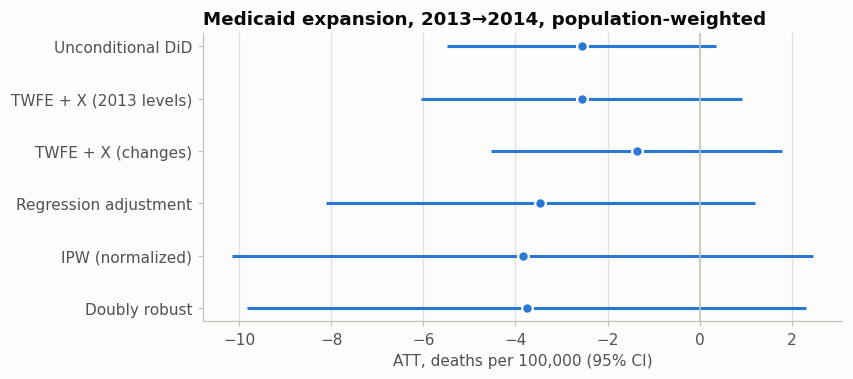

In [45]:
# Everything on one picture: population-weighted estimates with 95% CIs
summary = pd.DataFrame({
    "ATT": [twfe_x.loc[("Pop.-weighted", s), "β̂_treat"] for s in twfe_x.loc["Pop.-weighted"].index]
           + list(cov_table.loc["Pop.-weighted", "ATT"]),
    "SE": [twfe_x.loc[("Pop.-weighted", s), "SE"] for s in twfe_x.loc["Pop.-weighted"].index]
          + list(cov_table.loc["Pop.-weighted", "SE"]),
}, index=["Unconditional DiD", "TWFE + X (2013 levels)", "TWFE + X (changes)",
          "Regression adjustment", "IPW (normalized)", "Doubly robust"])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(summary))[::-1]
ax.hlines(y, summary["ATT"] - 1.96 * summary["SE"], summary["ATT"] + 1.96 * summary["SE"], color=BLUE, lw=2)
ax.plot(summary["ATT"], y, "o", color=BLUE, ms=7, mec=SURFACE, mew=1.5)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(y, summary.index)
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_xlabel("ATT, deaths per 100,000 (95% CI)")
ax.set_title("Medicaid expansion, 2013→2014, population-weighted")
plt.show()

**What we learned** (guide §4 and Lecture 6)
- All covariate-adjusted estimates are negative but imprecise: county-level mortality data have limited power.
- Our six covariates predict **who expanded** much better than they predict **mortality trends** (guide, Table 6). RA, IPW and DR still disagree somewhat, especially unweighted: the modelling choices matter, which is why DR's protection is valuable.
- Covariates matter for **credibility** even when they barely move the point estimate: the design phase (balance, overlap) is part of the analysis.
- Recommended default: **DR** with pre-treatment covariates, after checking overlap. Report RA and IPW as robustness.

---
## 7 · Wrap-up  *(3 min)*

1. **Identification:** SUTVA + no anticipation + parallel trends ⇒ the ATT equals a difference of two changes in means.
2. **Estimation:** four means = pooled OLS = TWFE = first differences in the 2×2. The regression adds convenience, not identification.
3. **Inference:** cluster at least by unit; ask what is random in your design.
4. **Weights:** they define the target parameter. Choose them for the question, not for the result.
5. **Covariates:** check balance and overlap; if you need conditional PT, estimate the identification formula (RA / IPW / **DR**) rather than adding $X$ to TWFE.

### Exit ticket (hand in on Canvas)
1. In one sentence each, state the ATT and the parallel-trends assumption **for the Medicaid example**, in words a policymaker would understand.
2. The unweighted and weighted DiDs are +0.1 and −2.6. A classmate says "the result isn't robust to weighting." What is wrong with that statement?
3. Give one covariate you would **not** condition on in this application and explain why (think: could Medicaid expansion itself have changed it?).

**Next lab:** many periods and staggered adoption. We will see when a single TWFE coefficient stops being an average treatment effect, and how Callaway & Sant'Anna (2021) rebuild everything from the 2×2 blocks you computed today.

---
## Appendix (optional) · Where the standard errors come from

Lecture 5 shows that the 2×2 DiD estimator is asymptotically linear with **influence function**
$$\psi_i = \frac{D_i}{p}\big(\Delta Y_i - \mu_{\Delta,T}\big) - \frac{1-D_i}{1-p}\big(\Delta Y_i - \mu_{\Delta,C}\big), \qquad \widehat{SE} = \sqrt{\frac{1}{n^2}\sum_{i=1}^n \hat\psi_i^2}.$$
Each county gets a signed "credit" for the estimate. The clustered regression SE is (up to small-sample corrections) exactly this. The **multiplier bootstrap** perturbs the influence function with random weights instead of re-estimating, which is how the `did` package builds its confidence bands.

In [46]:
dY, Dd = ld["dy"].to_numpy(), ld["treat"].to_numpy()
p_hat = Dd.mean()
mu_T, mu_C = dY[Dd == 1].mean(), dY[Dd == 0].mean()
psi = Dd / p_hat * (dY - mu_T) - (1 - Dd) / (1 - p_hat) * (dY - mu_C)
n = len(dY)
se_if = np.sqrt(np.mean(psi ** 2) / n)
print(f"DiD = {mu_T - mu_C:.3f};  influence-function SE = {se_if:.3f};  clustered regression SE = {reg_table.loc[('Unweighted', '(2) TWFE'), 'SE (county-clustered)']:.3f}")

# Multiplier bootstrap: theta* = theta + mean(U_i * psi_i), U_i ~ N(0,1)
rng = np.random.default_rng(521)
draws = np.array([np.mean(rng.standard_normal(n) * psi) for _ in range(999)])
print(f"Multiplier-bootstrap SE (999 draws) = {draws.std():.3f}")

DiD = 0.122;  influence-function SE = 3.746;  clustered regression SE = 3.748
Multiplier-bootstrap SE (999 draws) = 3.810
